In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
from tqdm import tqdm
import seaborn as sns
pd.set_option('display.max_columns', None)

## Do it via the known output:

In [9]:
cf = pd.read_pickle("../03_clear_cases/clear-fusion_tama_augustus.pkl")
cf["gene_id"]=cf["accession"]+"_"+cf["gene"]
cf["isoform_id"]=cf["accession"]+"_"+cf["isoform"]

In [11]:
lengths=pd.DataFrame()
for acc in tqdm(cf["accession"].unique().tolist()):
    # -------------1-------------
    # prepare sqanti output
    sqanti = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/{}_augustus_sqanti/{}-tama-vs-augustus_classification.txt".format(acc,acc), sep="\t")
    sqanti["gene"] = sqanti["isoform"].str.split(".").str[0]
    sqanti["isoform_id"] = acc+"_"+sqanti["isoform"]
    sub = sqanti[["ORF_length","CDS_length","isoform_id"]]
    lengths=pd.concat([lengths,sub])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:37<00:00,  2.11s/it]


In [12]:
cf=pd.merge(cf, lengths, on=["isoform_id"], how="left")

In [13]:
cf

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs,gene_id,isoform_id,ORF_length,CDS_length
0,G1128,G1128.10,at6923,g1555,novel,1,3275,1,59,genic,mono-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0,at6923_G1128,at6923_G1128.10,393.0,1182.0
1,G1128,G1128.11,at6923,g1555,novel,1,2744,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0,at6923_G1128,at6923_G1128.11,395.0,1188.0
2,G1128,G1128.12,at6923,g1555,novel,1,2795,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0,at6923_G1128,at6923_G1128.12,395.0,1188.0
3,G1128,G1128.13,at6923,g1555,novel,1,1821,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0,at6923_G1128,at6923_G1128.13,395.0,1188.0
4,G1128,G1128.2,at6923,g1555,novel,2,3331,1,59,novel_not_in_catalog,intron_retention,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0,at6923_G1128,at6923_G1128.2,393.0,1182.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3408192,G16302,G16302.24,col0,ATCG01310_ATCG01300,novel,2,818,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,2.0,col0_G16302,col0_G16302.24,253.0,759.0
3408193,G16302,G16302.26,col0,ATCG01310_ATCG01300,novel,2,831,2,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0,col0_G16302,col0_G16302.26,257.0,771.0
3408194,G16302,G16302.5,col0,ATCG01310_ATCG01300,novel,2,1204,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0,col0_G16302,col0_G16302.5,257.0,771.0
3408195,G16302,G16302.7,col0,ATCG01310_ATCG01300,novel,2,1141,6,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0,col0_G16302,col0_G16302.7,257.0,771.0


In [440]:
def get_template():
    template={
        #general: calculate mean
        "exons":0,
        "length":0,
        #"gene_read_support":0,
        #structural_category
        "genic":0,
        "novel_not_in_catalog":0,
        "full-splice_match":0,
        "incomplete-splice_match":0,
        "novel_in_catalog":0,
        #add extra
        "fusion":0,
        #subcategory
        'mono-exon':0,
        'intron_retention':0,
        'alternative_3end5end':0,
        '3prime_fragment':0,
        'at_least_one_novel_splicesite':0,
        'mono-exon_by_intron_retention':0,
        '5prime_fragment':0,
        'alternative_3end':0,
        'internal_fragment':0,
        'alternative_5end':0,
        'multi-exon':0,
        'reference_match':0,
        'combination_of_known_splicesites':0,
        'combination_of_known_junctions':0,
        #calculate total from df
        "n_ORFs":0,
        "n_isoforms":0,
        "n_noncoding":0,
        # calculate mean, get from squanti direct
        "ORF_length":0,
        "CDS_length":0
    }
    return template

In [443]:
def gene_from_iso(g):
    df=g[1]
    gene=get_template()
    #general:
    gene["exons"]=df["exons"].apply("mean")
    gene["length"]=df["length"].apply("mean")
    #structural_category:
    cat=df["structural_category"].value_counts().rename_axis('unique_values').reset_index(name='counts')
    for c in cat["unique_values"].unique().tolist():
        gene[c]+=cat.loc[cat["unique_values"]==c]["counts"].astype(int).tolist()[0]

    #subcategory:
    subcat=df["subcategory"].value_counts().rename_axis('unique_values').reset_index(name='counts')
    for sc in subcat["unique_values"].unique().tolist():
        gene[sc]+=subcat.loc[subcat["unique_values"]==sc]["counts"].astype(int).tolist()[0]

    #calculate from df:
    gene["n_ORFs"]=len(df["Sqanti_ORF_seq"].dropna().unique())
    gene["n_isoforms"]=len(df)
    gene["n_noncoding"]=df["Sqanti_ORF_seq"].isna().sum()
    
    # more:
    gene["ORF_length"]=df["ORF_length"].apply("mean")
    gene["CDS_length"]=df["CDS_length"].apply("mean")
    
    out=pd.DataFrame.from_dict([gene])
    out["gene"]=g[0]
    return out

In [444]:
PCA_genes=pd.DataFrame()
for g in tqdm(cf.groupby("gene_id")):
    gene=gene_from_iso(g)
    PCA_genes=pd.concat([PCA_genes, gene], ignore_index=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 282538/282538 [1:18:47<00:00, 59.76it/s]


In [456]:
PCA_genes=PCA_genes.reset_index(drop=True)


In [726]:
PCA_genes.to_pickle("PCA_genes.pkl")

In [14]:
PCA_genes = pd.read_pickle("PCA_genes.pkl")

In [15]:
t=[]
for g in tqdm(cf.groupby("gene_id")):
    if "nlr" in g[1]["type"].tolist():
        t.append("nlr")
    else:
        t.append("other")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 282538/282538 [00:10<00:00, 26068.34it/s]


In [16]:
PCA_genes

,exons,length,genic,novel_not_in_catalog,full-splice_match,incomplete-splice_match,novel_in_catalog,fusion,mono-exon,intron_retention,alternative_3end5end,3prime_fragment,at_least_one_novel_splicesite,mono-exon_by_intron_retention,5prime_fragment,alternative_3end,internal_fragment,alternative_5end,multi-exon,reference_match,combination_of_known_splicesites,combination_of_known_junctions,n_ORFs,n_isoforms,n_noncoding,ORF_length,CDS_length,gene,type
0,6.000000,1625.500000,0,0,2,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,1,2,0,429.000000,1290.000000,at6923_G1,other
1,2.727273,1518.863636,2,1,16,3,0,0,2,1,11,2,1,0,0,5,0,0,0,0,0,0,5,22,0,391.863636,1178.590909,at6923_G10,other
2,2.000000,1686.000000,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,3,0,443.000000,1332.000000,at6923_G100,other
3,9.833333,1258.916667,0,3,9,0,0,0,0,2,4,0,1,0,0,5,0,0,0,0,0,0,4,12,0,304.416667,916.250000,at6923_G1000,other
4,2.375000,1753.500000,6,0,2,0,0,0,2,0,0,0,0,0,0,0,0,0,6,0,0,0,2,8,0,317.250000,954.750000,at6923_G10000,other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282533,7.625000,2574.475000,1,5,19,15,0,0,1,0,1,14,5,0,1,1,0,11,0,6,0,0,8,40,1,654.435897,1966.307692,col0_G9995,other
282534,7.029412,2215.764706,0,3,31,0,0,0,0,0,3,0,3,0,0,12,0,7,0,9,0,0,4,34,0,590.970588,1775.911765,col0_G9996,other
282535,4.833333,2230.333333,0,0,5,0,1,0,0,1,0,0,0,0,0,1,0,1,0,3,0,0,3,6,0,560.333333,1684.000000,col0_G9997,other
282536,9.833333,1708.833333,0,0,5,0,1,0,0,1,0,0,0,0,0,1,0,1,0,3,0,0,2,6,0,427.166667,1284.500000,col0_G9998,other


In [17]:
t_df=PCA_genes[["gene","type"]].copy()

## PCA

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np

In [19]:
# define gene sets
PCA_genes_struct=PCA_genes[['exons', 'length', 'n_ORFs', 'n_isoforms', 'n_noncoding', 'ORF_length', 'CDS_length','gene','type']]
PCA_genes_splice=PCA_genes[['genic', 'novel_not_in_catalog', 'full-splice_match','incomplete-splice_match', 'novel_in_catalog', 'fusion',
                            'mono-exon','intron_retention', 'alternative_3end5end', '3prime_fragment','at_least_one_novel_splicesite', 'mono-exon_by_intron_retention','5prime_fragment', 'alternative_3end',
                            'internal_fragment','alternative_5end', 'multi-exon', 'reference_match','combination_of_known_splicesites', 'combination_of_known_junctions','gene','type']]
PCA_genes_cat=PCA_genes[['genic', 'novel_not_in_catalog', 'full-splice_match','incomplete-splice_match', 'novel_in_catalog', 'fusion','gene','type']]
#PCA_genes_subcat=
# define subsets
PCA_genes_struct_col0=PCA_genes_struct.loc[PCA_genes_struct["gene"].str.split("_").str[0]=="col0"]
PCA_genes_cat_col0=PCA_genes_cat.loc[PCA_genes_cat["gene"].str.split("_").str[0]=="col0"]
#PCA_genes_struct_at9900=

In [20]:
# first try: scale + pca
# https://stackoverflow.com/questions/25475465/how-to-normalize-with-pca-and-scikit-learn
# and https://www.jcchouinard.com/pca-with-python/
Y = PCA_genes_cat_col0.loc[:, ['gene','type']]
X = PCA_genes_cat_col0.drop(['gene','type'], axis=1)
X.fillna(0, inplace=True)

scaler = StandardScaler()
scaler.fit(X) 
X_scaled = scaler.transform(X)

pca = PCA(n_components=3)
pca.fit(X_scaled) 
X_pca = pca.transform(X_scaled) 

ex_variance=np.var(X_pca,axis=0)
ex_variance_ratio = ex_variance/np.sum(ex_variance)
ex_variance_ratio

array([0.47374662, 0.33240696, 0.19384641])

In [21]:
# Principal Components Weights (Eigenvectors)
df_pca_loadings = pd.DataFrame(pca.components_)
df_pca_loadings

,0,1,2,3,4,5
0,0.517187,0.198536,0.578416,0.272671,0.292724,0.445532
1,0.370426,-0.541130,0.050062,-0.535481,-0.405891,0.340541
2,-0.104940,-0.094442,-0.197333,-0.493465,0.813963,0.187308


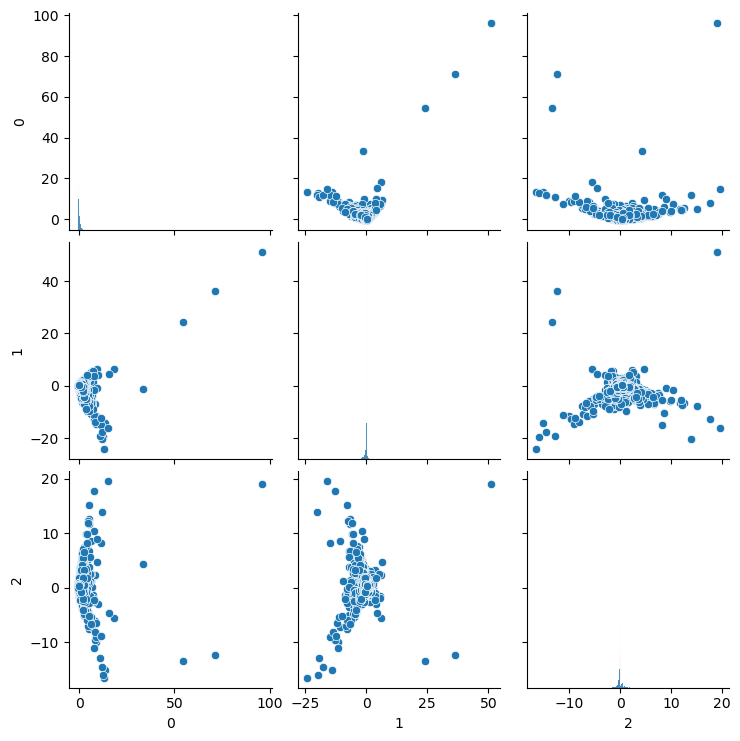

In [22]:
X_pca.shape

pc_df = pd.DataFrame(X_pca)
sns.pairplot(pc_df);

In [23]:
Y["type"]

266907    other
266908    other
266909    other
266910    other
266911    other
          ...  
282533    other
282534    other
282535    other
282536    other
282537    other
Name: type, Length: 15631, dtype: object

In [24]:
pc_df

,0,1,2
0,-0.477726,0.064610,0.420366
1,-0.452649,0.434842,-0.090295
2,0.205157,-0.103961,0.242006
3,-0.093976,0.465885,-0.212661
4,0.053528,-1.419783,0.231416
...,...,...,...
15626,2.168587,-2.053876,-2.031294
15627,1.226996,-0.396809,-0.710064
15628,-0.269326,0.180647,0.419461
15629,-0.269326,0.180647,0.419461


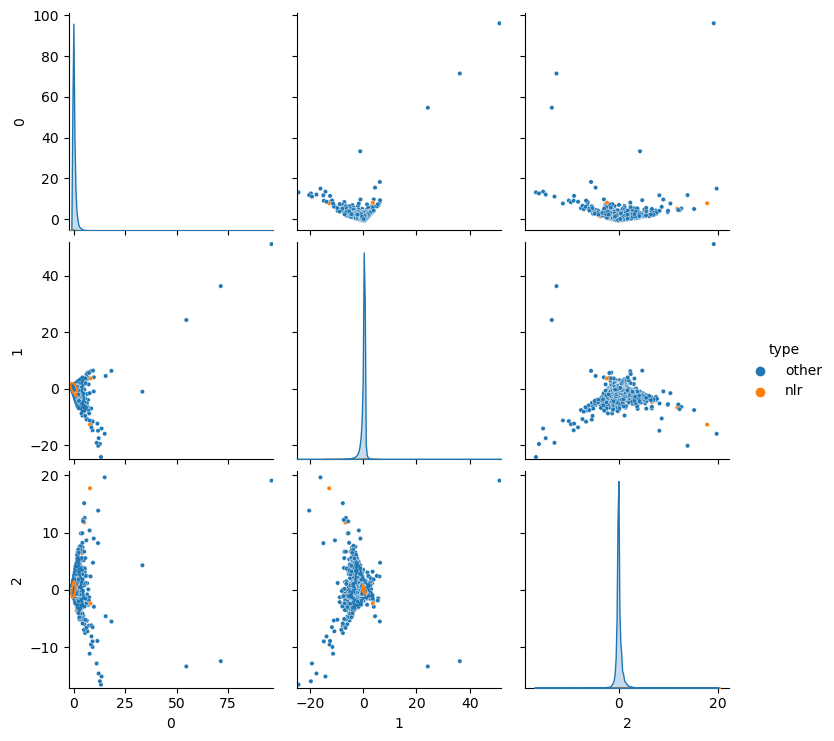

In [25]:
pc_df["type"]=Y["type"].tolist()
g=sns.pairplot(pc_df, hue="type",  plot_kws={"s": 10})
g.map_lower(sns.kdeplot, levels=4, color=".2")

In [26]:
g.savefig("col0_PCA.png")

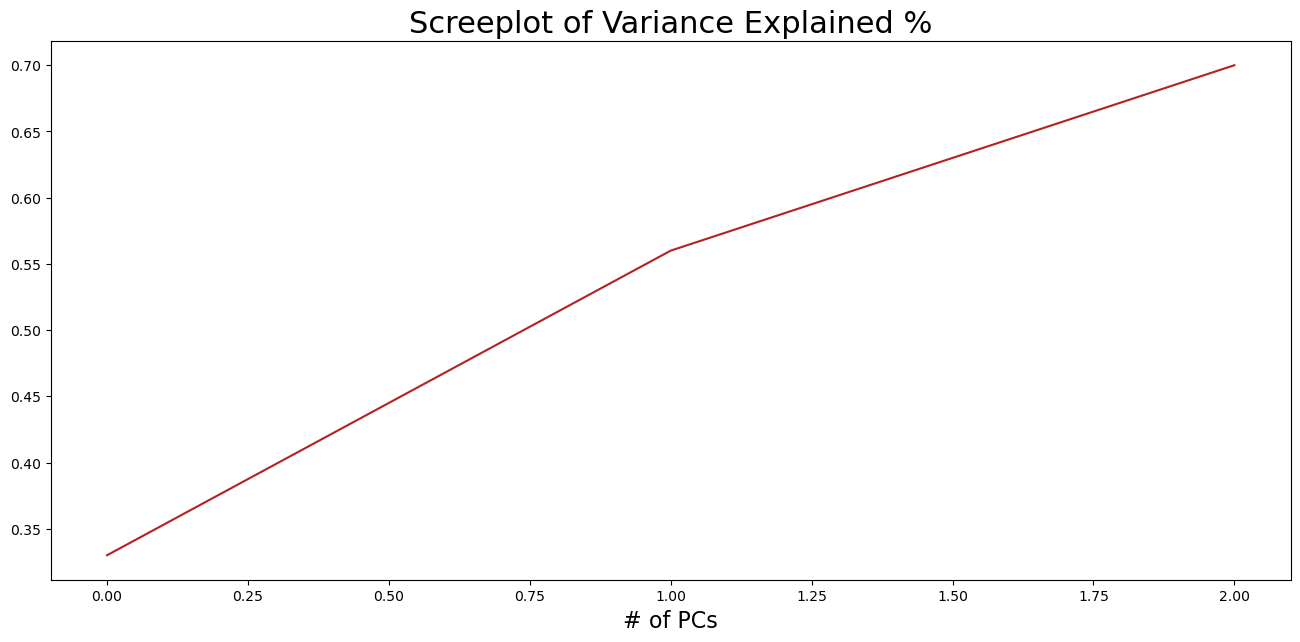

In [1073]:
variance_exp_cumsum = pca.explained_variance_ratio_.cumsum().round(2)
fig, axes = plt.subplots(1,1,figsize=(16,7), dpi=100)
plt.plot(variance_exp_cumsum, color='firebrick')
plt.title('Screeplot of Variance Explained %', fontsize=22)
plt.xlabel('# of PCs', fontsize=16)
plt.show()

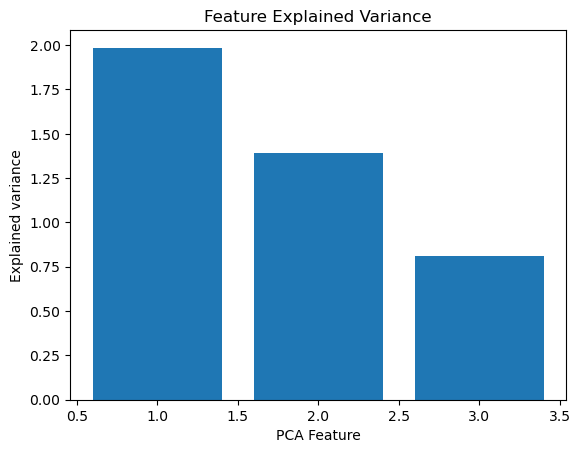

In [1074]:
# Bar plot of explained_variance
plt.bar(
    range(1,len(pca.explained_variance_)+1),
    pca.explained_variance_
)
 
 

plt.xlabel('PCA Feature')
plt.ylabel('Explained variance')
plt.title('Feature Explained Variance')
plt.show()

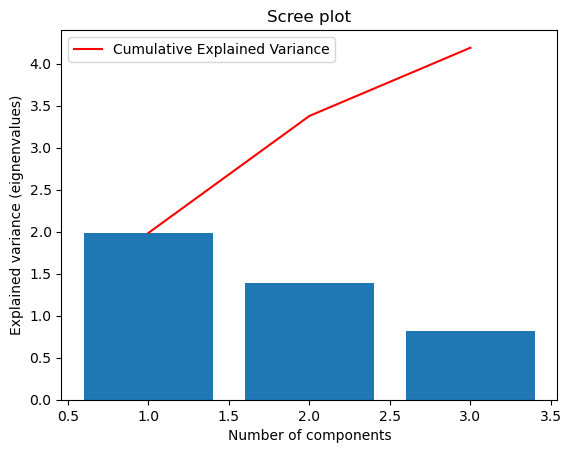

In [1075]:
# Bar plot of explained_variance
plt.bar(
    range(1,len(pca.explained_variance_)+1),
    pca.explained_variance_
    )
 
plt.plot(
    range(1,len(pca.explained_variance_ )+1),
    np.cumsum(pca.explained_variance_),
    c='red',
    label='Cumulative Explained Variance')
 
plt.legend(loc='upper left')
plt.xlabel('Number of components')
plt.ylabel('Explained variance (eignenvalues)')
plt.title('Scree plot')
 
plt.show()

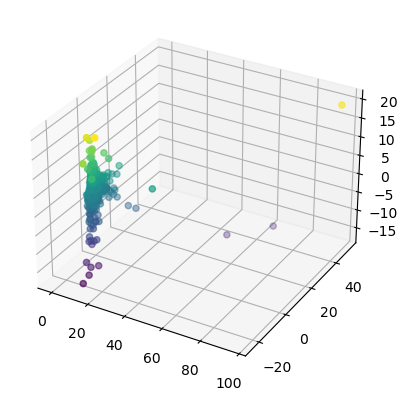

In [1076]:
import numpy as np
import matplotlib.pyplot as plt
 
from mpl_toolkits import mplot3d
plt.style.use('default')
 
# Prepare 3D graph
fig = plt.figure()
ax = plt.axes(projection='3d')
 
# Plot scaled features
xdata = X_pca[:,0]
ydata = X_pca[:,1]
zdata = X_pca[:,2]
 
# Plot 3D plot
ax.scatter3D(xdata, ydata, zdata, c=zdata)
 
# Plot title of graph
#plt.title(f'3D Scatter of Iris')
 
# Plot x, y, z even ticks
#ticks = np.linspace(-3, 3, num=5)
#ax.set_xticks(ticks)
#ax.set_yticks(ticks)
#ax.set_zticks(ticks)
 
# Plot x, y, z labels
#ax.set_xlabel('sepal_length', rotation=150)
#ax.set_ylabel('sepal_width')
#ax.set_zlabel('petal_length', rotation=60)
#plt.show()

In [707]:
# Principal components correlation coefficients
loadings = pca.components_
 
# Number of features before PCA
n_features = pca.n_features_in_
 
# Feature names before PCA
feature_names = X.columns
 
# PC names
pc_list = [f'PC{i}' for i in list(range(1, n_features + 1))]
 
# Match PC names to loadings
pc_loadings = dict(zip(pc_list, loadings))
 
# Matrix of corr coefs between feature names and PCs
loadings_df = pd.DataFrame.from_dict(pc_loadings)
loadings_df['feature_names'] = feature_names
loadings_df = loadings_df.set_index('feature_names')
loadings_df

,PC1,PC2,PC3,PC4,PC5
feature_names,,,,,
exons,0.312375,-0.048001,-0.528914,0.783862,0.071845
length,0.491673,-0.170044,0.209894,-0.029653,-0.064694
n_ORFs,0.335791,0.412084,-0.437950,-0.348459,-0.632349
n_isoforms,0.209766,0.652008,-0.103200,-0.174029,0.694917
n_noncoding,0.026235,0.549000,0.618313,0.466084,-0.306376
ORF_length,0.501619,-0.190324,0.213845,-0.088698,0.083564
CDS_length,0.501610,-0.190339,0.213786,-0.088714,0.083838


## Sklearn - OneHotEncoding

In [ ]:
#https://datagy.io/pandas-get-dummies/
#https://datagy.io/sklearn-one-hot-encode/
#https://stackoverflow.com/questions/36631163/what-are-the-pros-and-cons-between-get-dummies-pandas-and-onehotencoder-sciki
#https://stackoverflow.com/questions/66644733/how-to-add-your-own-categories-into-the-onehotencoder

enc = OneHotEncoder(categories=[['mono-exon', 'intron_retention', 'alternative_3end5end',
       '3prime_fragment', 'at_least_one_novel_splicesite',
       'mono-exon_by_intron_retention', '5prime_fragment',
       'alternative_3end', 'internal_fragment', 'alternative_5end',
       'multi-exon', 'reference_match',
       'combination_of_known_splicesites',
       'combination_of_known_junctions']])

enc_test=OneHotEncoder(sparse=False)
test=enc_test.fit(k[["subcategory"]])
print(enc_test.transform(k[["subcategory"]]))